In [1]:
# script to model CBS data
# last update Peter Berrill 9/3/2025

# load in required packages
import numpy as np
import pandas as pd
import shap
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold, cross_validate, GroupKFold, StratifiedGroupKFold, RepeatedKFold, StratifiedKFold, GridSearchCV, KFold
from sklearn import metrics, linear_model
from xgboost import XGBClassifier, XGBRegressor
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import seaborn as sns

This notebook demonstrates a few things. 

1. Examining the set of predictor/independent variables to look for large correlation issues
2. Preparing data for modelling with OLS regression and GBDT models
3. Cross validation to estimate best hyperparameters in GBDT model
4. A repeated k-fold cross validation to estimate performance of the model robustly (without training on the whole dataset), during which we estimate average shap values (explainers for the GBDT model) and regression coefficients
5. Visualisation of variable influence and importance derived from the SHAP values

# Exploration of GHG

## Defining dependent & independent variables

In [2]:
year = '2019'

classification = 'income' #alternative: 'tenure', 'income'
if classification == 'income':
    lab = 'inc_lab'
    class_name = 'income level'
    class_name_short = 'income'
    class_name_long = 'equivalised income level'
    class_col = 'inc_decile'
else: #if tenure
    lab = 'tenure_lab'
    class_name = 'tenure'
    class_name_short = 'tenure'
    class_name_long = 'tenure'
    class_col = str('tenure'+year)

df=pd.read_csv('data_input/output/use'+classification+year+'.csv', index_col=[0,1,2,3,4])
dep = pd.read_csv('data_processed/ghg_annual_per_cap'+classification+year+'.csv', index_col=[0,1,2,3,4])
df['kg_CO2e_per_capita'] = dep.sum(1) #total ghg footprint for housing
df['m3_gas_per_capita'] = df['gas'+year]/df['mean_hhd']
df['kWh_electricity_per_capita'] = df['netelectricity'+year]/df['mean_hhd']
df['mean_cars'] = (df['car_hhd']/df['n_adultmem'+year]) #normalising car ownership by number of households
df['heatpump_pc'] = (df['n_heatpump'+year]/df['n_hhd']).fillna(0)
df['districtheating_pc'] = (df['n_cityheating'+year]/df['n_hhd']).fillna(0)
if classification == 'tenure':
    df['tenure'+year].replace(2, 3.1, inplace=True)
    df['tenure'+year].replace(3, 2.1, inplace=True)
    df['tenure'+year].replace(3.1, 3, inplace=True)
    df['tenure'+year].replace(2.1, 2, inplace=True)
df.reset_index(inplace=True)
df.columns

Index(['inc_lab', 'typology_lab', 'const_lab', 'density_lab',
       'distance_train_lab', 'inc_decile', 'typology4_2019', 'const_cat2019',
       'density2019', 'q_distance_train2019', 'size2019_w1', 'size2019_sd',
       'size2019_med', 'size2019pp_w1', 'size2019pp_sd', 'size2019pp_med',
       'addresses2019', 'addresses2019_sd', 'addresses2019_med', 'n_hhd',
       'n_hhdmem2019', 'n_adultmem2019', 'n_childmem2019',
       'distance_train2019', 'distance_train2019_sd', 'distance_train2019_med',
       'distance_depstore2019', 'distance_depstore2019_sd',
       'distance_depstore2019_med', 'distance_supermarket2019',
       'distance_supermarket2019_sd', 'distance_supermarket2019_med',
       'distance_middleschool2019', 'distance_middleschool2019_sd',
       'distance_middleschool2019_med', 'electricity2019',
       'electricity2019_sd', 'electricity2019_med', 'netelectricity2019',
       'netelectricity2019_sd', 'netelectricity2019_med', 'gas2019',
       'gas2019_sd', 'gas2019_me

In [3]:
# collect here the independent (predictor) variables, both in original format and with all categoricals converted to numeric
ind_vars=[lab,'typology_lab','const_lab','density_lab','distance_train'+year,'distance_depstore'+year,'distance_supermarket'+year,'distance_middleschool'+year,
          'mean_hhd','size'+year+'pp_w1','mean_cars',
          #'districtheating_pc', 
          'heatpump_pc',
          ]
ind_vars_num=[class_col,'typology4_'+year,'const_cat'+year,'density'+year,'distance_train'+year,'distance_depstore'+year,'distance_supermarket'+year,'distance_middleschool'+year,
          'mean_hhd','size'+year+'pp_w1','mean_cars',
          #'districtheating_pc', 
          'heatpump_pc',
          ]
dep_var= 'kWh_electricity_per_capita'  #'kg_CO2e_per_capita' #'netelectricity'+year

## Checking for multicollinearity

In [204]:
# check for correlation among predictor variables, and variance inflation factor - which indicates how big an issue multicollinearity is for each variable.
# preferable to keep VIF < ~5 when possible

# all variables, a combination of the numeric independent variables and the dependent variable
all_var=ind_vars_num.copy()
all_var.append(dep_var)
df0=df.loc[:,all_var]

# drop rows with NA values. We do this after defining df0, because if we did it with the whole df we would lose rows due to NAs that are not in the variables we are interested in
df0=df0.dropna()
X=df0.loc[:,ind_vars_num]
X_selc = add_constant(X)
vif=pd.Series([variance_inflation_factor(X_selc.values, i) for i in range(X_selc.shape[1])], index=X_selc.columns)
vif=vif.to_frame().reset_index()
vif.columns=['Feature','VIF']
corr = X.corr()
print(vif)
corr.abs().style.format(precision=3).background_gradient(cmap='coolwarm')

                      Feature         VIF
0                       const  291.677531
1                  inc_decile    1.367358
2              typology4_2019    3.735590
3               const_cat2019    1.376476
4                 density2019    5.373515
5          distance_train2019    1.786976
6       distance_depstore2019   14.973745
7    distance_supermarket2019    3.336401
8   distance_middleschool2019   21.456747
9                    mean_hhd    3.296922
10              size2019pp_w1    2.903991
11                  mean_cars    1.216897
12                heatpump_pc    1.319004


,inc_decile,typology4_2019,const_cat2019,density2019,distance_train2019,distance_depstore2019,distance_supermarket2019,distance_middleschool2019,mean_hhd,size2019pp_w1,mean_cars,heatpump_pc
inc_decile,1.000,0.014,0.006,0.008,0.021,0.026,0.074,0.007,0.367,0.011,0.062,0.028
typology4_2019,0.014,1.000,0.011,0.038,0.010,0.062,0.218,0.067,0.557,0.576,0.215,0.059
const_cat2019,0.006,0.011,1.000,0.015,0.013,0.059,0.114,0.031,0.229,0.110,0.050,0.460
density2019,0.008,0.038,0.015,1.000,0.089,0.817,0.714,0.856,0.006,0.244,0.194,0.013
distance_train2019,0.021,0.010,0.013,0.089,1.000,0.204,0.092,0.346,0.018,0.007,0.068,0.069
distance_depstore2019,0.026,0.062,0.059,0.817,0.204,1.000,0.765,0.950,0.047,0.162,0.120,0.005
distance_supermarket2019,0.074,0.218,0.114,0.714,0.092,0.765,1.000,0.734,0.246,0.308,0.056,0.073
distance_middleschool2019,0.007,0.067,0.031,0.856,0.346,0.950,0.734,1.000,0.036,0.197,0.136,0.009
mean_hhd,0.367,0.557,0.229,0.006,0.018,0.047,0.246,0.036,1.000,0.030,0.114,0.124
size2019pp_w1,0.011,0.576,0.110,0.244,0.007,0.162,0.308,0.197,0.030,1.000,0.262,0.108


In [4]:
# updating variables

# without middleschool and department store
ind_vars=[lab,'typology_lab','const_lab','density_lab','distance_train'+year,'distance_depstore'+year,'distance_supermarket'+year,#'distance_middleschool'+year,
          'mean_hhd','size'+year+'pp_w1','mean_cars',
          #'districtheating_pc', 
          'heatpump_pc',
          ]
ind_vars_num=[class_col,'typology4_'+year,'const_cat'+year,'density'+year,'distance_train'+year,'distance_depstore'+year,'distance_supermarket'+year,#'distance_middleschool'+year,
          'mean_hhd','size'+year+'pp_w1','mean_cars',
          #'districtheating_pc', 
          'heatpump_pc',
          ]

all_var=ind_vars_num.copy()
all_var.append(dep_var)
df0=df.loc[:,all_var]
df0=df0.dropna()

# additional check for multicollinearity
X=df0.loc[:,ind_vars_num]
X_selc = add_constant(X)
vif=pd.Series([variance_inflation_factor(X_selc.values, i) for i in range(X_selc.shape[1])], index=X_selc.columns)
vif=vif.to_frame().reset_index()
vif.columns=['Feature','VIF']
corr = X.corr()
print(vif)
corr.abs().style.format(precision=3).background_gradient(cmap='coolwarm')

                     Feature         VIF
0                      const  284.373006
1                 inc_decile    1.366178
2             typology4_2019    3.733572
3              const_cat2019    1.374681
4                density2019    3.637955
5         distance_train2019    1.085260
6      distance_depstore2019    4.334921
7   distance_supermarket2019    3.308403
8                   mean_hhd    3.286468
9              size2019pp_w1    2.883959
10                 mean_cars    1.216383
11               heatpump_pc    1.318784


,inc_decile,typology4_2019,const_cat2019,density2019,distance_train2019,distance_depstore2019,distance_supermarket2019,mean_hhd,size2019pp_w1,mean_cars,heatpump_pc
inc_decile,1.000,0.014,0.006,0.008,0.021,0.026,0.074,0.367,0.011,0.062,0.028
typology4_2019,0.014,1.000,0.011,0.038,0.010,0.062,0.218,0.557,0.576,0.215,0.059
const_cat2019,0.006,0.011,1.000,0.015,0.013,0.059,0.114,0.229,0.110,0.050,0.460
density2019,0.008,0.038,0.015,1.000,0.089,0.817,0.714,0.006,0.244,0.194,0.013
distance_train2019,0.021,0.010,0.013,0.089,1.000,0.204,0.092,0.018,0.007,0.068,0.069
distance_depstore2019,0.026,0.062,0.059,0.817,0.204,1.000,0.765,0.047,0.162,0.120,0.005
distance_supermarket2019,0.074,0.218,0.114,0.714,0.092,0.765,1.000,0.246,0.308,0.056,0.073
mean_hhd,0.367,0.557,0.229,0.006,0.018,0.047,0.246,1.000,0.030,0.114,0.124
size2019pp_w1,0.011,0.576,0.110,0.244,0.007,0.162,0.308,0.030,1.000,0.262,0.108
mean_cars,0.062,0.215,0.050,0.194,0.068,0.120,0.056,0.114,0.262,1.000,0.068


## Dummify categorical variables

In [5]:
#for ordinal analysis
df1=df0.copy() # this is the one for OLS, which can handle categorical variables
y=df0[dep_var]
X=df0.drop(columns=dep_var)

# define the OLS regression equation
form_str=dep_var+" ~ "+class_col+" + typology4_"+year+" + const_cat"+year+" + density"+year+" + distance_train"+year+" + distance_supermarket"+year+" + distance_depstore"+year+" + mean_hhd + size"+year+"pp_w1 + mean_cars + heatpump_pc"
#form_str=dep_var+" ~ "+class_col+" + typology4_"+year+" + const_cat"+year+" + density"+year+" + mean_hhd + size"+year+"pp_w1 + districtheating_pc + heatpump_pc"

In [187]:
# # for the categorical variables in the GBDT model, we should dummify them: income, typology, construction year, and density

# # append the dependent (outcome) variables to the list of independent variables (categorical version)
# all_var=ind_vars.copy()
# all_var.append(dep_var)

# df0=df.loc[:,all_var]
# # remove NAs
# df0=df0.dropna() 
# df1=df0.copy() # this is the one for OLS, which can handle categorical variables

# # convert  all categorical variables to dummies
# df_Cat=df0.loc[:,[lab,'typology_lab','const_lab','density_lab']]
# for col in df_Cat:
#     dum=pd.get_dummies(df0[[col]])
#     df0 = pd.concat([df0, dum], axis = 1)

# # this is the df needed for ML models, e.g. xgboost
# df0.drop(columns=[lab,'typology_lab','const_lab','density_lab'],inplace=True)
# y=df0[dep_var]
# X=df0.drop(columns=dep_var)
# X

# # define the OLS regression equation
# form_str=dep_var+" ~ C("+lab+",Treatment(reference='decile 1 (poorest)')) + C(typology_lab,Treatment(reference='detached')) + C(const_lab,Treatment(reference='pre 1945')) + C(density_lab,Treatment(reference='rural'))  + distance_train"+year+" + distance_depstore"+year+" + distance_supermarket"+year+" + mean_hhd + size"+year+"pp_w1 + mean_cars"

## GBTD Model parameter calibration via cross validation

In [208]:
# do a cross validation to estimate the best hyperparameters for use in a GBDT model
# here we are seeing the values of hyperparameters 'learning rate', 'number of estimators' i.e. number of trees, and 'max depth' (max amount of interaction between variables considered)
# which give the best performance (prediction on unseen values). basically it is fine tuning to give a gradient boosting tree model with best predictive power

cv = RepeatedKFold(n_splits=5,n_repeats=8,random_state=1)
PS = {"learning_rate": [0.01, 0.05,0.1,0.2], 
        "n_estimators": [100,200, 300],
        "max_depth":[2,3,4]}

tuning_all = GridSearchCV(estimator=XGBRegressor(verbosity=0), param_grid=PS, cv=cv, scoring="r2",return_train_score=True)
tuning_all.fit(X,y)

print('best hyper-parameters identified by HPO')
print(tuning_all.best_params_)
print('r2 with best hyper-parameters')
print(tuning_all.best_score_)
cv_res_all=tuning_all.cv_results_

n_parameter_all = tuning_all.best_params_['n_estimators']
lr_parameter_all = tuning_all.best_params_['learning_rate']
md_parameter_all = tuning_all.best_params_['max_depth']

best hyper-parameters identified by HPO
{'learning_rate': 0.2, 'max_depth': 4, 'n_estimators': 300}
r2 with best hyper-parameters
0.889664368789477


In [ ]:
# only need to do the above step once, it is time intensive
# electricity: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300}
# ghg categorical: {'learning_rate': 0.2, 'max_depth': 4, 'n_estimators': 300}
# ghg ordinal: {'learning_rate': 0.2, 'max_depth': 4, 'n_estimators': 300}
# ghg ordinal tenure: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300}
# gas ordinal income: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 300}
# gas ordinal income w/o building type: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}
# gas ordinal income 2023: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300}
# electricity ordinal income 2019: {'learning_rate': 0.2, 'max_depth': 4, 'n_estimators': 300}
n_parameter_all = 300
lr_parameter_all = 0.2
md_parameter_all = 4

In [7]:
# then we run our models (OLS regression and xgboost) numerous times, each time with a model trained on 80% of the data and tested on the remaining 20%
# We collecte and estimate average regression coefficients and average shap values from the OLS and xgboost models respectively

# define a cross validation function for splitting up the dataset into train and test sets. 
# this is repeated a number of times (5 here)
cv = RepeatedKFold(n_splits=5,n_repeats=5,random_state=2)

# predefine some lists & dataframes
y_predict = pd.DataFrame()
y_predict2 = pd.DataFrame()
y_test = pd.DataFrame()
y_test2 = pd.DataFrame()
summ_table_list=[]

shap_values= pd.DataFrame() 

model = XGBRegressor(
max_depth=md_parameter_all, 
n_estimators=n_parameter_all, 
learning_rate=lr_parameter_all)

# if doing the repeated cv and creation of shap values, pre-define lists to store r2 values
r2ml=[]
r2lr=[]

for train_idx, test_idx in cv.split(X): # select here 
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test_fold = y.iloc[train_idx], y.iloc[test_idx]
        df_train, df_test = df1.iloc[train_idx], df1.iloc[test_idx] 
        y_test_fold2=df_test[dep_var]

        # train & predict GBDT model
        model.fit(X_train, y_train, verbose=False, eval_set=[(X_train, y_train), (X_test, y_test_fold)])
        y_predict_fold = pd.Series(model.predict(X_test), index=X_test.index)
        r2ml.extend([metrics.r2_score(y_test_fold.array, y_predict_fold.array)])
        # explain
        explainer = shap.TreeExplainer(model)
        shap_values_fold = explainer.shap_values(X_test,check_additivity=False)
        shap_values_fold = pd.DataFrame(shap_values_fold, index=X_test.index, columns=X.columns) 

        y_predict = pd.concat([y_predict, y_predict_fold], axis=0)
        y_test = pd.concat([y_test, y_test_fold], axis=0)

        shap_values = pd.concat([shap_values, shap_values_fold], axis=0)
        
        # estimate OLS model
        lin_reg = smf.ols(form_str, data=df_train).fit()
        yhat=np.asarray(lin_reg.predict(df_test.drop(columns=dep_var)))
        y_predict_fold2 = pd.Series(yhat, index=df_test.index)
        y_predict2 = pd.concat([y_predict2, y_predict_fold2], axis=0)
        y_test2 = pd.concat([y_test2, y_test_fold2], axis=0)
        
        r2lr.extend([metrics.r2_score(y_test_fold.array, y_predict_fold2.array)])

        # get the coefficents and p values of the regression
        coeff=lin_reg.params.reset_index()
        coeff.rename(columns={'index':'param',0:'coefficient'},inplace=True)
        pval=lin_reg.pvalues.reset_index()
        pval.rename(columns={'index':'param',0:'p'},inplace=True)
        summ_table=pd.concat([coeff,pval['p']],axis=1)

        st_list_fold=[summ_table.drop(columns='param').to_numpy()]
        summ_table_list.append(st_list_fold)

# save the summary regression table with average coefficients
mdarray=np.array(summ_table_list).squeeze()
means=np.nanmean(mdarray,axis=0)
means_df=pd.DataFrame(data=np.hstack((np.reshape(summ_table['param'].to_numpy(),(len(summ_table),1)),means)),columns=summ_table.columns.values)
means_df.to_csv('data_processed/OLS_summary_'+dep_var+year+classification+'.csv',index=False)

y_test = y_test.squeeze(axis=1)
y_test2 = y_test2.squeeze(axis=1)
y_predict = y_predict.squeeze(axis=1)
y_predict2 = y_predict2.squeeze(axis=1)
r2_model=metrics.r2_score(y_test, y_predict)
r2_model_reg=metrics.r2_score(y_test2, y_predict2)

# get the average importance ranking, either manually or using the shap built-in functions (can be slightly different results).
shap_values_abs=abs(shap_values)
shap_sum = shap_values_abs.mean(axis=0)
importance_df = pd.DataFrame([shap_sum]).T
importance_df.reset_index(inplace=True)
importance_df.rename(columns={'index':'feature',0:'shap_importance'},inplace=True)
importance_df = importance_df.sort_values('shap_importance', ascending=False)
importance_df['cont_pc']=100*importance_df['shap_importance']/importance_df['shap_importance'].sum()
importance_df.to_csv('data_processed/SHAP_summary_'+dep_var+year+classification+'.csv',index=False)

# summarise mean importance as estimated by shap values
shap_values=shap_values.sort_index()
shap_values.reset_index(inplace=True)
shap_values=shap_values.groupby('index').mean().reset_index()
shap_values.drop(columns=['index'],inplace=True)
shap_values.to_csv('data_processed/SHAP_values_'+dep_var+year+classification+'.csv',index=False)

# print and compare the peformance of the gradient boosting and OLS models
print('GBDT Model r2: ')
print(r2_model)
print('LR Model r2: ')
print(r2_model_reg)


GBDT Model r2: 
0.8885465662991284
LR Model r2: 
0.7620136528340962


## Display results

In [8]:
# OLS regression results
means_df.sort_values('coefficient')

,param,coefficient,p
8,mean_hhd,-207.980634,0.0
11,heatpump_pc,-74.804294,0.355935
4,density2019,-13.909581,0.0
2,typology4_2019,-6.478905,0.022101
3,const_cat2019,-2.313959,0.032529
7,distance_depstore2019,-0.01497,0.0
5,distance_train2019,0.003971,0.0
6,distance_supermarket2019,0.06807,0.0
9,size2019pp_w1,9.852367,0.0
10,mean_cars,12.014514,0.0


In [217]:
importance_df

,feature,shap_importance,cont_pc
8,size2019pp_w1,89.260338,29.061399
7,mean_hhd,66.145958,21.535814
1,typology4_2019,27.747017,9.033879
0,inc_decile,27.608219,8.988690
2,const_cat2019,24.583502,8.003901
4,distance_train2019,18.904692,6.154993
9,mean_cars,15.464395,5.034901
6,distance_supermarket2019,14.390633,4.685305
5,distance_depstore2019,11.234403,3.657699
3,density2019,9.191821,2.992675


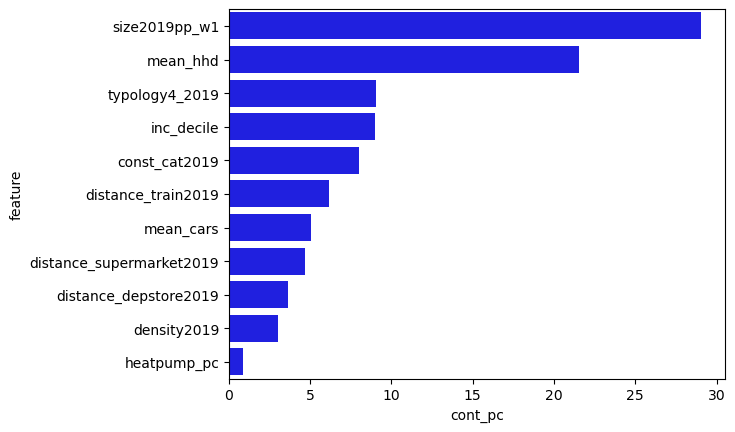

 99%|===================| 5749/5800 [00:43<00:00]        

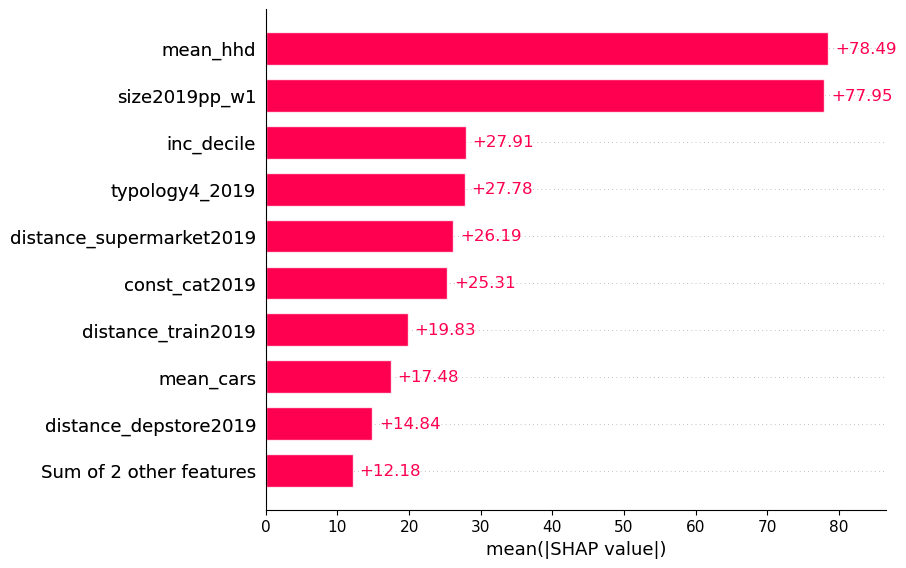

<Figure size 640x480 with 0 Axes>

In [9]:
# plot barlot of importance of each variable to the predicted outcome in the GBDT, measured in contribution percent
# this shows us the importance, but not the direction of influence of each variable
sns.barplot(data=importance_df.iloc[:12,], x='cont_pc', y='feature',color='blue')
plt.show()
plt.savefig('visualisations/barchart_shap_contribution_pc_'+dep_var+year+classification+'.svg')

# then the built in approach for showing variable importance, calculated different to the manual approach so can give different outputs, but tends to be broadly similar.
explainer = shap.Explainer(model, X)
shap_values_ex = explainer(X)
shap.plots.bar(shap_values_ex)
plt.show()
plt.savefig('visualisations/barchart_shap_mean_'+dep_var+year+classification+'.svg')

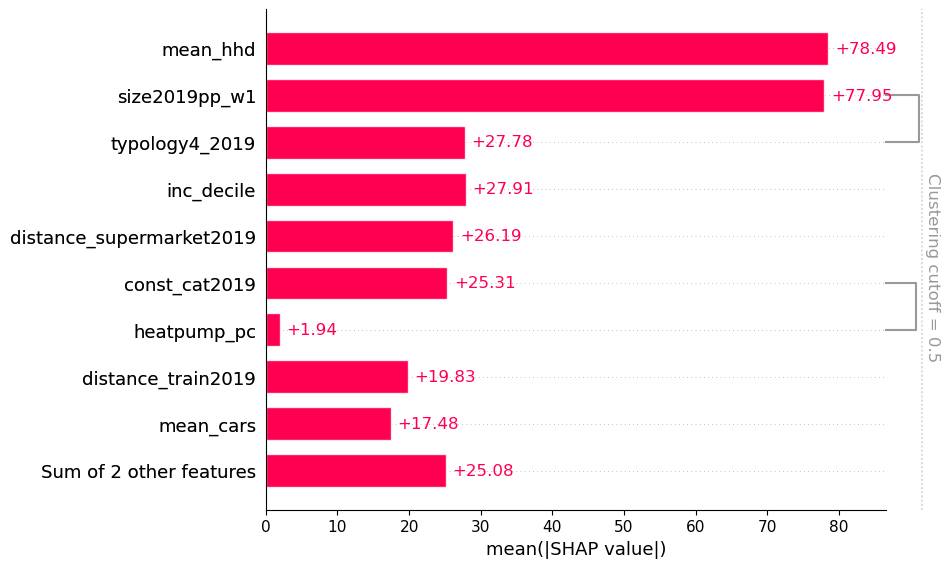

<Figure size 640x480 with 0 Axes>

In [10]:
#again the built in approach for showing variable imnportance, this time including clustering among related variabels
clustering = shap.utils.hclust(X, y)
shap.plots.bar(shap_values_ex, clustering=clustering)
plt.savefig('visualisations/barchart_shap_relatedvars_'+dep_var+year+classification+'.svg')

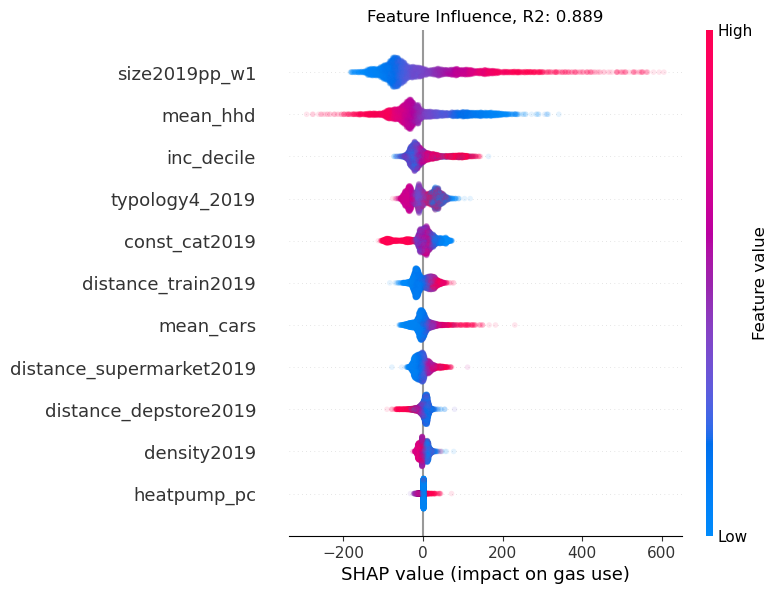

In [11]:
# plot influences over the range of each predictor value, ranked by importance
shap.summary_plot(shap_values.sort_index().to_numpy(), X.sort_index(),max_display=14,show=False, alpha=0.1)
plt.title('Feature Influence, R2: ' + round(r2_model,3).astype(str))
plt.xlabel("SHAP value (impact on gas use)")
plt.savefig('visualisations/violin_shap_range_'+dep_var+year+classification+'.svg')

0
1
2
3
4
5
6
7
8


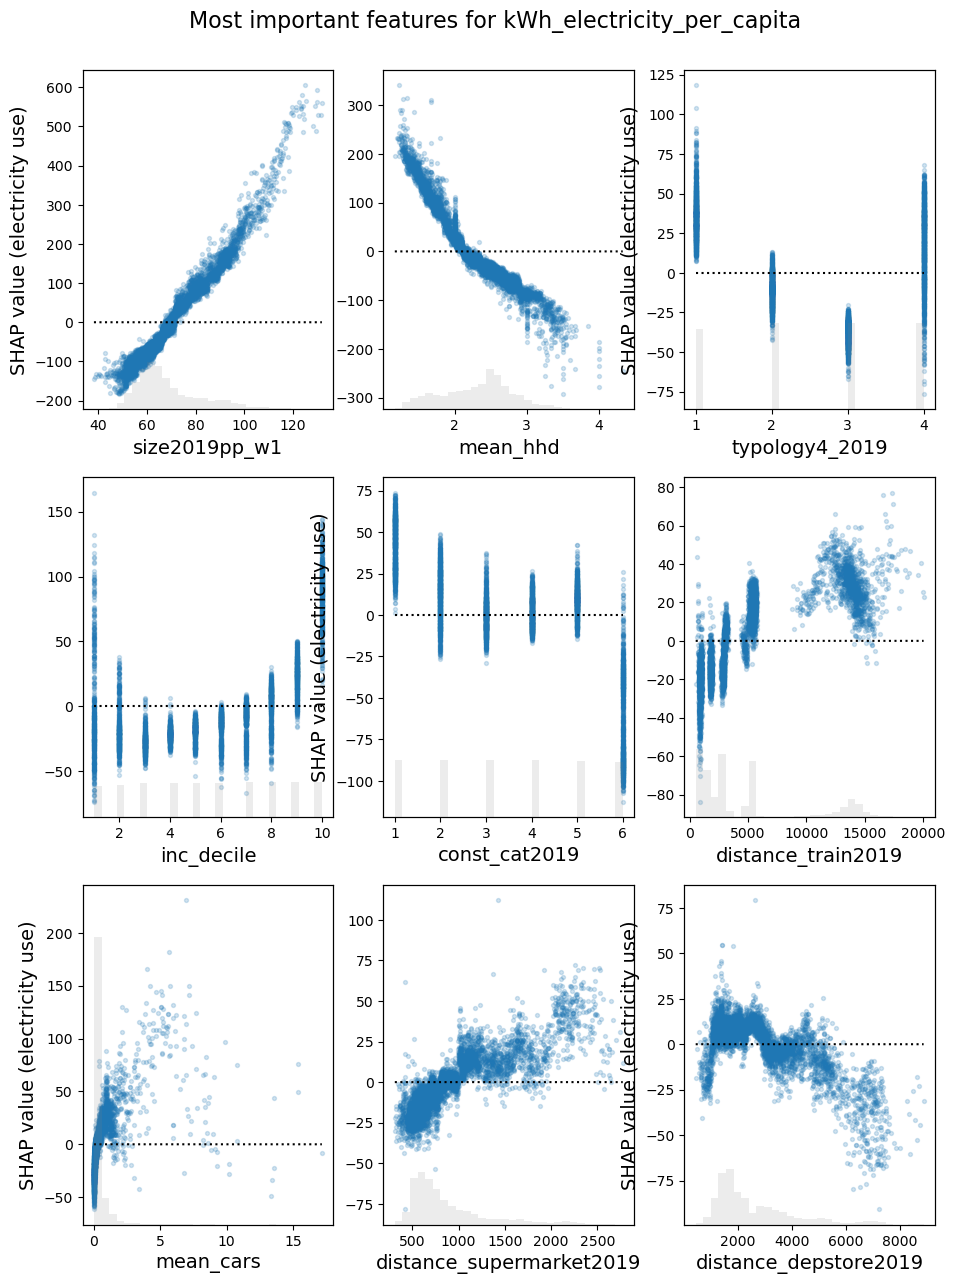

In [12]:
# then show the range of influences (shap values) over the range of the x values
# this has the benefit of allowing us to see the direction of influence and potential non-linear influence of variables
n=importance_df[:10].index

X.sort_index(inplace=True)
data=X.sort_index().iloc[:,n]
values=shap_values.sort_index().iloc[:,n]

xl=[]
yl=[]
y0=[]

for i in range(len(n)):
        dftemp=pd.DataFrame({'d':data.iloc[:,i],'v':values.iloc[:,i]})
        dftemp=dftemp.groupby('d')['v'].mean().reset_index()
        dftemp['v0']=0
        xl.append(dftemp['d'].values)
        yl.append(dftemp['v'].values)
        y0.append(dftemp['v0'].values)

# plot the conditional shap values (accounting for influences of other variables) for the top N most influential variables.
# here we choose the top 8. this can be changed by altering the range, and then the dimensions of the subplot (42 for 8, 32 for 6, etc.)

fig = plt.figure(figsize=(11,15))
for i in range(0,[len(ind_vars_num) if len(ind_vars_num)<=9 else 9][0]):
        print(i)
        ax1 = fig.add_subplot(331+i)
        xs=data.iloc[:,i]
        ys=values.iloc[:,i]
        x=xl[i]
        y1=y0[i]
        y2=yl[i]
        xlab=data.columns[i]

        ax1.scatter(xs,ys,alpha=0.2,s=8)
        plt.plot(x,y1,'k:',label='zero')

        if i%2==0:
                ax1.set_ylabel('SHAP value (electricity use)',size=14)
        else:
                ax1.set_ylabel('')
        ax1.set_xlabel(xlab,size=14)

        ax2 = ax1.twinx() 
        if len(xs.unique())==2:
                ax2.hist(xs,bins=[-0.5,0.5,1.5], align='mid',color='gray',alpha=0.25)
                ax2.set_xticks([-.5,0,0.5,1,1.5])
        else:
                ax2.hist(xs,bins=30,color='gray',alpha=0.15)
                ax2.set_ylim(0,len(data))
        ax2.set_yticks([])
plt.suptitle("Most important features for "+dep_var,y=0.92,size=16)
plt.savefig('visualisations/scatter_shap_range_'+dep_var+year+classification+'.png')

# Example Exploration (case study: electricity consumption)

In [197]:
df=pd.read_csv('data_input/output/useincome2019.csv')
df.head()

,inc_lab,typology_lab,const_lab,density_lab,distance_train_lab,inc_decile,typology4_2019,const_cat2019,density2019,q_distance_train2019,...,mean_adult,mean_child,car_pkm,car_vkm,transit_pkm,walk_pkm,cycle_pkm,car_hhd,n_mem_per_hhd_mobility,mem_weight
0,decile 1 (poorest),detached,pre 1945,very urban,nearest quintile,1,1,1,1,1,...,1.576923,0.423077,4247.667220,6992.496324,7129.468653,1308.866833,2370.373222,132.355848,1.346312,1.171291
1,decile 1 (poorest),detached,pre 1945,very urban,2nd quintile,1,1,1,1,2,...,1.500000,0.307692,4372.128418,10995.609397,4185.676820,1070.230566,2682.131037,116.804315,1.361251,1.101927
2,decile 1 (poorest),detached,pre 1945,very urban,3nd quintile,1,1,1,1,3,...,1.777778,0.444444,4256.914232,6013.919829,3482.835568,1476.210630,2953.929017,135.323995,1.392543,1.276641
3,decile 1 (poorest),detached,pre 1945,very urban,4nd quintile,1,1,1,1,4,...,1.400000,NaN,5587.139042,9200.445980,1420.888837,873.453565,2234.893944,80.483819,1.408979,0.993627
4,decile 1 (poorest),detached,pre 1945,very urban,furthest quintile,1,1,1,1,5,...,NaN,NaN,NaN,1986.064735,NaN,NaN,NaN,NaN,1.337209,NaN


In [198]:
df.columns

Index(['inc_lab', 'typology_lab', 'const_lab', 'density_lab',
       'distance_train_lab', 'inc_decile', 'typology4_2019', 'const_cat2019',
       'density2019', 'q_distance_train2019', 'size2019_w1', 'size2019_sd',
       'size2019_med', 'size2019pp_w1', 'size2019pp_sd', 'size2019pp_med',
       'addresses2019', 'addresses2019_sd', 'addresses2019_med', 'n_hhd',
       'n_hhdmem2019', 'n_adultmem2019', 'n_childmem2019',
       'distance_train2019', 'distance_train2019_sd', 'distance_train2019_med',
       'distance_depstore2019', 'distance_depstore2019_sd',
       'distance_depstore2019_med', 'distance_supermarket2019',
       'distance_supermarket2019_sd', 'distance_supermarket2019_med',
       'distance_middleschool2019', 'distance_middleschool2019_sd',
       'distance_middleschool2019_med', 'electricity2019',
       'electricity2019_sd', 'electricity2019_med', 'netelectricity2019',
       'netelectricity2019_sd', 'netelectricity2019_med', 'gas2019',
       'gas2019_sd', 'gas2019_me

In [199]:
# collect here the independent (predictor) variables, both in original format and with all categoricals converted to numeric
ind_vars=[lab,'typology_lab','const_lab','density_lab','distance_train'+year,'distance_depstore'+year,'distance_supermarket'+year,'distance_middleschool'+year,
          'mean_hhd']
ind_vars_num=[class_col,'typology4_'+year,'const_cat'+year,'density'+year,'distance_train'+year,'distance_depstore'+year,'distance_supermarket'+year,'distance_middleschool'+year,
          'mean_hhd']
dep_var='netelectricity'+year
# all variables, a combination of the numeric independent variables and the dependent variable
all_var=ind_vars_num.copy()
all_var.append(dep_var)

df0=df.loc[:,all_var]

# drop rows with NA values. We do this after defining df0, because if we did it with the whole df we would lose rows due to NAs that are not in the variables we are interested in
df0=df0.dropna()
df1=df0.copy() # this is the one for OLS, which can handle categorical variables

KeyError: "['tenure2019'] not in index"

In [ ]:
# check for correlation among predictor variables, and variance inflation factor - which indicates how big an issue multicollinearity is for each variable.
# preferable to keep VIF < ~5 when possible
X_selc = add_constant(X)
vif=pd.Series([variance_inflation_factor(X_selc.values, i) for i in range(X_selc.shape[1])], index=X_selc.columns)
vif=vif.to_frame().reset_index()
vif.columns=['Feature','VIF']
corr = X.corr()
print(vif)
corr.abs().style.format(precision=3).background_gradient(cmap='coolwarm')

                     Feature        VIF
0                      const  67.784451
1                 inc_decile   1.284336
2             typology4_2019   1.645520
3              const_cat2019   1.118934
4                density2019   5.184730
5         distance_train2019   1.747557
6      distance_depstore2019  14.117758
7   distance_supermarket2019   2.935877
8  distance_middleschool2019  21.000018
9                   mean_hhd   2.074052


,inc_decile,typology4_2019,const_cat2019,density2019,distance_train2019,distance_depstore2019,distance_supermarket2019,distance_middleschool2019,mean_hhd
inc_decile,1.000,0.014,0.006,0.018,0.007,0.054,0.059,0.030,0.373
typology4_2019,0.014,1.000,0.011,0.038,0.010,0.061,0.221,0.065,0.556
const_cat2019,0.006,0.011,1.000,0.015,0.013,0.058,0.110,0.030,0.229
density2019,0.018,0.038,0.015,1.000,0.075,0.819,0.713,0.858,0.019
distance_train2019,0.007,0.010,0.013,0.075,1.000,0.185,0.085,0.329,0.011
distance_depstore2019,0.054,0.061,0.058,0.819,0.185,1.000,0.757,0.949,0.031
distance_supermarket2019,0.059,0.221,0.110,0.713,0.085,0.757,1.000,0.731,0.238
distance_middleschool2019,0.030,0.065,0.030,0.858,0.329,0.949,0.731,1.000,0.023
mean_hhd,0.373,0.556,0.229,0.019,0.011,0.031,0.238,0.023,1.000


In [ ]:
# remove middle school, as it is highly correlated with dist to department store, and it has a high VIF.
ind_vars=[lab,'typology_lab','const_lab','density_lab','distance_train'+year,'distance_depstore'+year,'distance_supermarket'+year,
          'mean_hhd']
ind_vars_num=[class_col,'typology4_'+year,'const_cat'+year,'density'+year,'distance_train'+year,'distance_depstore'+year,'distance_supermarket'+year,
          'mean_hhd']
dep_var='netelectricity'+year
all_var=ind_vars_num.copy()
all_var.append(dep_var)

df0=df.loc[:,all_var]
df0=df0.dropna()
df1=df0.copy() # this is the one for OLS, which can handle categorical variables

X=df0.loc[:,ind_vars_num]

X_selc = add_constant(X)
vif=pd.Series([variance_inflation_factor(X_selc.values, i) for i in range(X_selc.shape[1])], index=X_selc.columns)
vif=vif.to_frame().reset_index()
vif.columns=['Feature','VIF']
corr = X.corr()
print(vif)
corr.abs().style.format(precision=3).background_gradient(cmap='coolwarm')

                    Feature        VIF
0                     const  65.878824
1                inc_decile   1.279294
2            typology4_2019   1.638868
3             const_cat2019   1.116801
4               density2019   3.417226
5        distance_train2019   1.059070
6     distance_depstore2019   4.003699
7  distance_supermarket2019   2.926855
8                  mean_hhd   2.074049


,inc_decile,typology4_2019,const_cat2019,density2019,distance_train2019,distance_depstore2019,distance_supermarket2019,mean_hhd
inc_decile,1.000,0.014,0.006,0.018,0.007,0.054,0.059,0.373
typology4_2019,0.014,1.000,0.011,0.038,0.010,0.061,0.221,0.556
const_cat2019,0.006,0.011,1.000,0.015,0.013,0.058,0.110,0.229
density2019,0.018,0.038,0.015,1.000,0.075,0.819,0.713,0.019
distance_train2019,0.007,0.010,0.013,0.075,1.000,0.185,0.085,0.011
distance_depstore2019,0.054,0.061,0.058,0.819,0.185,1.000,0.757,0.031
distance_supermarket2019,0.059,0.221,0.110,0.713,0.085,0.757,1.000,0.238
mean_hhd,0.373,0.556,0.229,0.019,0.011,0.031,0.238,1.000


In [ ]:
# distance to supermarket and department store are highest (or have highest range) for lowest density category
round(X_selc.groupby('density'+year)['distance_train'+year,'distance_depstore'+year,'distance_supermarket'+year].median())

/var/folders/__/twfrdq8n75n5f0118_f882700000gn/T/ipykernel_56008/2977800872.py:2: FutureWarning: Indexing with multiple keys (implicitly converted to a tuple of keys) will be deprecated, use a list instead.
  round(X_selc.groupby('density2019')['distance_train2019','distance_depstore2019','distance_supermarket2019'].median())


,distance_train2019,distance_depstore2019,distance_supermarket2019
density2019,,,
1,2810.0,1473.0,549.0
2,2891.0,1672.0,650.0
3,2908.0,1816.0,726.0
4,2932.0,3082.0,814.0
5,3096.0,5015.0,1573.0


In [ ]:
round(X_selc.groupby('density'+year)['distance_train'+year,'distance_depstore'+year,'distance_supermarket'+year].mean())

/var/folders/__/twfrdq8n75n5f0118_f882700000gn/T/ipykernel_56008/13999622.py:1: FutureWarning: Indexing with multiple keys (implicitly converted to a tuple of keys) will be deprecated, use a list instead.
  round(X_selc.groupby('density2019')['distance_train2019','distance_depstore2019','distance_supermarket2019'].mean())


,distance_train2019,distance_depstore2019,distance_supermarket2019
density2019,,,
1,4036.0,1438.0,566.0
2,4799.0,1680.0,683.0
3,5011.0,1835.0,759.0
4,5114.0,3101.0,840.0
5,5155.0,5202.0,1622.0


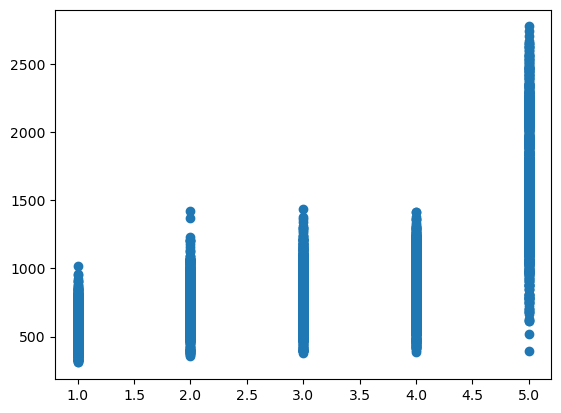

In [ ]:
plt.scatter(X_selc['density'+year],X_selc['distance_supermarket'+year])

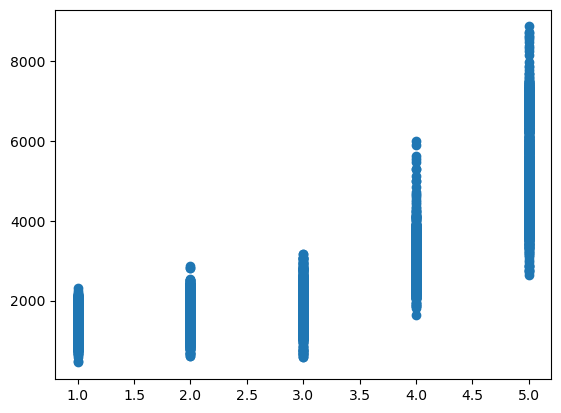

In [ ]:
plt.scatter(X_selc['density'+year],X_selc['distance_depstore'+year])

2. Now prepare the data in appropriate formats for OLS and GBDT models

In [ ]:
# append the dependent (outcome) variables to the list of independent variables (categorical version)
all_var=ind_vars.copy()
all_var.append(dep_var)

df0=df.loc[:,all_var]
# remove NAs
df0=df0.dropna() 
df1=df0.copy() # this is the one for OLS, which can handle categorical variables


In [ ]:
# for the categorical variables in the GBDT model, we should dummify them: income, typology, construction year, and density

# convert  all categorical variables to dummies
df_Cat=df0.loc[:,[lab,'typology_lab','const_lab','density_lab']]
for col in df_Cat:
    dum=pd.get_dummies(df0[[col]])
    df0 = pd.concat([df0, dum], axis = 1)

# this is the df needed for ML models, e.g. xgboost
df0.drop(columns=[lab,'typology_lab','const_lab','density_lab'],inplace=True)
y=df0[dep_var]
X=df0.drop(columns=dep_var)
X


,distance_train2019,distance_depstore2019,distance_supermarket2019,mean_hhd,inc_lab_decile 1 (poorest),inc_lab_decile 10 (richest),inc_lab_decile 2,inc_lab_decile 3,inc_lab_decile 4,inc_lab_decile 5,...,const_lab_1965-1974,const_lab_1975-1991,const_lab_1992-2005,const_lab_2006-2022,const_lab_pre 1945,density_lab_high suburban,density_lab_low suburban,density_lab_rural,density_lab_urban,density_lab_very urban
0,948.224806,1029.038760,490.713165,2.000000,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
1,1733.565891,1228.930233,513.945740,1.807692,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,2853.361702,1287.106383,712.170227,2.222222,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,5033.791667,1819.041667,897.791687,1.800000,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
5,865.161876,1160.587156,566.409058,2.121212,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5982,853.684211,2746.631579,1101.473633,2.000000,0,1,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0
5983,1875.727273,3602.681818,1317.045410,2.500000,0,1,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0
5984,3293.812500,4320.289062,2062.187500,2.038461,0,1,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0
5985,5461.755319,4812.691489,1746.432617,2.285714,0,1,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0


In [ ]:
# compare variables in the df0 data for the GBDT model vs the df1 data for the OLS model. 
# Should be the same variables, just varying how categorical variables are treated, as dummy variables (GBDT) or as categorical (OLS)

In [ ]:
df0.columns

Index(['distance_train2019', 'distance_depstore2019',
       'distance_supermarket2019', 'mean_hhd', 'netelectricity2019',
       'inc_lab_decile 1 (poorest)', 'inc_lab_decile 10 (richest)',
       'inc_lab_decile 2', 'inc_lab_decile 3', 'inc_lab_decile 4',
       'inc_lab_decile 5', 'inc_lab_decile 6', 'inc_lab_decile 7',
       'inc_lab_decile 8', 'inc_lab_decile 9', 'typology_lab_detached',
       'typology_lab_multifamily', 'typology_lab_row house',
       'typology_lab_semi-detached', 'const_lab_1946-1964',
       'const_lab_1965-1974', 'const_lab_1975-1991', 'const_lab_1992-2005',
       'const_lab_2006-2022', 'const_lab_pre 1945',
       'density_lab_high suburban', 'density_lab_low suburban',
       'density_lab_rural', 'density_lab_urban', 'density_lab_very urban'],
      dtype='object')

In [ ]:
df1.columns


Index(['inc_lab', 'typology_lab', 'const_lab', 'density_lab',
       'distance_train2019', 'distance_depstore2019',
       'distance_supermarket2019', 'mean_hhd', 'netelectricity2019'],
      dtype='object')

3. Here is the cross validation to estimate GBDT model hyperparameters

In [ ]:
# do a cross validation to estimate the best hyperparameters for use in a GBDT model
# here we are seeing the values of hyperparameters 'learning rate', 'number of estimators' i.e. number of trees, and 'max depth' (max amount of interaction between variables considered)
# which give the best performance (prediction on unseen values). basically it is fine tuning to give a gradient boosting tree model with best predictive power

# cv = RepeatedKFold(n_splits=5,n_repeats=8,random_state=1)
# PS = {"learning_rate": [0.01, 0.05,0.1,0.2], 
#         "n_estimators": [100,200, 300],
#         "max_depth":[2,3,4]}

# tuning_all = GridSearchCV(estimator=XGBRegressor(verbosity=0), param_grid=PS, cv=cv, scoring="r2",return_train_score=True)
# tuning_all.fit(X,y)

# print('best hyper-parameters identified by HPO')
# print(tuning_all.best_params_)
# print('r2 with best hyper-parameters')
# print(tuning_all.best_score_)
# cv_res_all=tuning_all.cv_results_

# n_parameter_all = tuning_all.best_params_['n_estimators']
# lr_parameter_all = tuning_all.best_params_['learning_rate']
# md_parameter_all = tuning_all.best_params_['max_depth']

pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
pandas.Int64Index is deprecated an

best hyper-parameters identified by HPO
{'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300}
r2 with best hyper-parameters
0.9299394601682234


In [ ]:
# only need to do the above step once, it is time intensive
n_parameter_all = 300
lr_parameter_all = 0.1
md_parameter_all = 4

In [ ]:
# then we run our models (OLS regression and xgboost) numerous times, each time with a model trained on 80% of the data and tested on the remaining 20%
# We collecte and estimate average regression coefficients and average shap values from the OLS and xgboost models respectively

# define a cross validation function for splitting up the dataset into train and test sets. 
# this is repeated a number of times (5 here)
cv = RepeatedKFold(n_splits=5,n_repeats=5,random_state=2)

# predefine some lists & dataframes
y_predict = pd.DataFrame()
y_predict2 = pd.DataFrame()
y_test = pd.DataFrame()
y_test2 = pd.DataFrame()
summ_table_list=[]

shap_values= pd.DataFrame() 

model = XGBRegressor(
max_depth=md_parameter_all, 
n_estimators=n_parameter_all, 
learning_rate=lr_parameter_all)

# if doing the repeated cv and creation of shap values, pre-define lists to store r2 values
r2ml=[]
r2lr=[]

In [ ]:
# define the OLS regression equation
form_str="netelectricity2019 ~ C("+lab+",Treatment(reference='decile 1 (poorest)')) + C(typology_lab,Treatment(reference='detached')) + C(const_lab,Treatment(reference='pre 1945')) + C(density_lab,Treatment(reference='rural'))  + distance_train2019 + distance_depstore2019 + distance_supermarket2019 + mean_hhd" 

for train_idx, test_idx in cv.split(X): # select here 
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test_fold = y.iloc[train_idx], y.iloc[test_idx]
        df_train, df_test = df1.iloc[train_idx], df1.iloc[test_idx] 
        y_test_fold2=df_test[dep_var]

        # train & predict GBDT model
        model.fit(X_train, y_train, verbose=False, eval_set=[(X_train, y_train), (X_test, y_test_fold)])
        y_predict_fold = pd.Series(model.predict(X_test), index=X_test.index)
        r2ml.extend([metrics.r2_score(y_test_fold.array, y_predict_fold.array)])
        # explain
        explainer = shap.TreeExplainer(model)
        shap_values_fold = explainer.shap_values(X_test,check_additivity=False)
        shap_values_fold = pd.DataFrame(shap_values_fold, index=X_test.index, columns=X.columns) 

        y_predict = pd.concat([y_predict, y_predict_fold], axis=0)
        y_test = pd.concat([y_test, y_test_fold], axis=0)

        shap_values = pd.concat([shap_values, shap_values_fold], axis=0)
        
        # estimate OLS model
        lin_reg = smf.ols(form_str, data=df_train).fit()
        yhat=np.asarray(lin_reg.predict(df_test.drop(columns=dep_var)))
        y_predict_fold2 = pd.Series(yhat, index=df_test.index)
        y_predict2 = pd.concat([y_predict2, y_predict_fold2], axis=0)
        y_test2 = pd.concat([y_test2, y_test_fold2], axis=0)
        
        r2lr.extend([metrics.r2_score(y_test_fold.array, y_predict_fold2.array)])

        # get the coefficents and p values of the regression
        coeff=lin_reg.params.reset_index()
        coeff.rename(columns={'index':'param',0:'coefficient'},inplace=True)
        pval=lin_reg.pvalues.reset_index()
        pval.rename(columns={'index':'param',0:'p'},inplace=True)
        summ_table=pd.concat([coeff,pval['p']],axis=1)

        st_list_fold=[summ_table.drop(columns='param').to_numpy()]
        summ_table_list.append(st_list_fold)

# save the summary regression table with average coefficients
mdarray=np.array(summ_table_list).squeeze()
means=np.nanmean(mdarray,axis=0)
means_df=pd.DataFrame(data=np.hstack((np.reshape(summ_table['param'].to_numpy(),(len(summ_table),1)),means)),columns=summ_table.columns.values)
means_df.to_csv('data_processed/OLS_summary_electricity.csv',index=False)

y_test = y_test.squeeze(axis=1)
y_test2 = y_test2.squeeze(axis=1)
y_predict = y_predict.squeeze(axis=1)
y_predict2 = y_predict2.squeeze(axis=1)
r2_model=metrics.r2_score(y_test, y_predict)
r2_model_reg=metrics.r2_score(y_test2, y_predict2)
# print and compare the peformance of the gradient boosting and OLS models
print('GBDT Model r2: ')
print(r2_model)
print('LR Model r2: ')
print(r2_model_reg)


GBDT Model r2: 
0.932515663506563
LR Model r2: 
0.8378453235452079


In [ ]:
# OLS regression results
means_df

,param,coefficient,p
0,Intercept,2151.735827,0.0
1,"C(inc_lab, Treatment(reference='decile 1 (poor...",495.818261,0.0
2,"C(inc_lab, Treatment(reference='decile 1 (poor...",-118.490793,0.0
3,"C(inc_lab, Treatment(reference='decile 1 (poor...",-133.822536,0.0
4,"C(inc_lab, Treatment(reference='decile 1 (poor...",-92.445555,0.0
5,"C(inc_lab, Treatment(reference='decile 1 (poor...",-53.38182,0.004234
6,"C(inc_lab, Treatment(reference='decile 1 (poor...",-29.987126,0.104244
7,"C(inc_lab, Treatment(reference='decile 1 (poor...",-5.084457,0.64137
8,"C(inc_lab, Treatment(reference='decile 1 (poor...",54.672151,0.002642
9,"C(inc_lab, Treatment(reference='decile 1 (poor...",145.292409,0.0


Text(0.5, 47.82222222222221, 'SHAP value (impact on outcome)')

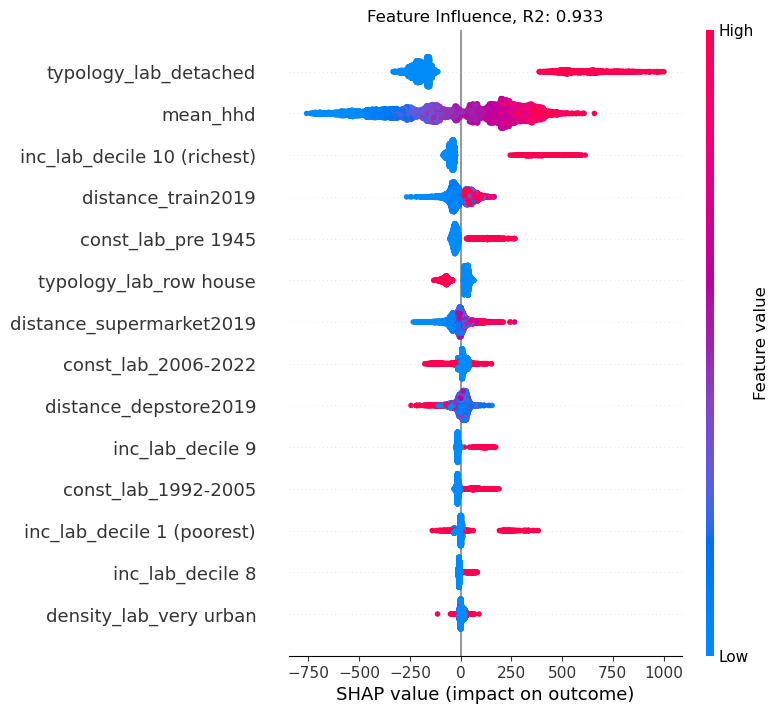

In [ ]:
# summarise mean importance as estimated by shap values
shap_values=shap_values.sort_index()
shap_values.reset_index(inplace=True)
shap_values=shap_values.groupby('index').mean().reset_index()
shap_values.drop(columns=['index'],inplace=True)

# plot influences over the range of each predictor value, ranked by importance
shap.summary_plot(shap_values.sort_index().to_numpy(), X.sort_index(),max_display=14,show=False)
plt.title('Feature Influence, R2: ' + round(r2_model,3).astype(str))
plt.xlabel("SHAP value (impact on outcome)")

In [ ]:
# get the average importance ranking, either manually or using the shap built-in functions (can be slightly different results).
shap_values_abs=abs(shap_values)
shap_sum = shap_values_abs.mean(axis=0)
importance_df = pd.DataFrame([shap_sum]).T
importance_df.reset_index(inplace=True)
importance_df.rename(columns={'index':'feature',0:'shap_importance'},inplace=True)
importance_df = importance_df.sort_values('shap_importance', ascending=False)
importance_df['cont_pc']=100*importance_df['shap_importance']/importance_df['shap_importance'].sum()
importance_df

,feature,shap_importance,cont_pc
14,typology_lab_detached,292.353912,28.972731
3,mean_hhd,250.665024,24.841297
5,inc_lab_decile 10 (richest),82.096100,8.135853
0,distance_train2019,43.478329,4.308771
23,const_lab_pre 1945,42.942600,4.255680
16,typology_lab_row house,42.007008,4.162961
2,distance_supermarket2019,34.303925,3.399573
22,const_lab_2006-2022,27.435776,2.718929
1,distance_depstore2019,25.384087,2.515603
13,inc_lab_decile 9,24.164614,2.394751


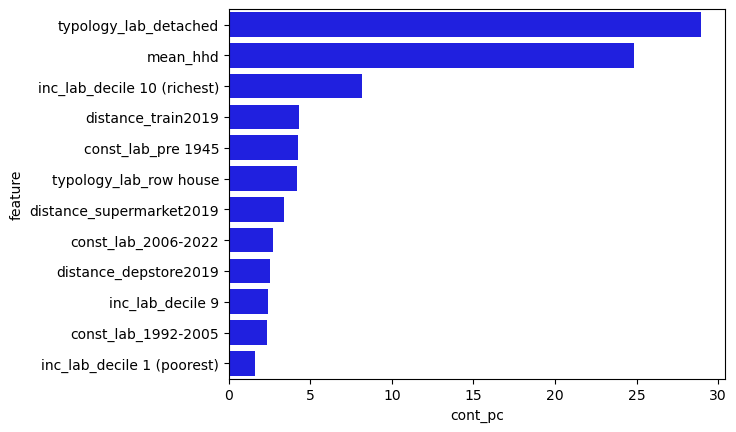

In [ ]:
# plot barlot of importance of each variable to the predicted outcome in the GBDT, measured in contribution percent
# this shows us the importance, but not the direction of influence of each variable
sns.barplot(data=importance_df.iloc[:12,], x='cont_pc', y='feature',color='blue')

 99%|===================| 5825/5872 [00:44<00:00]        

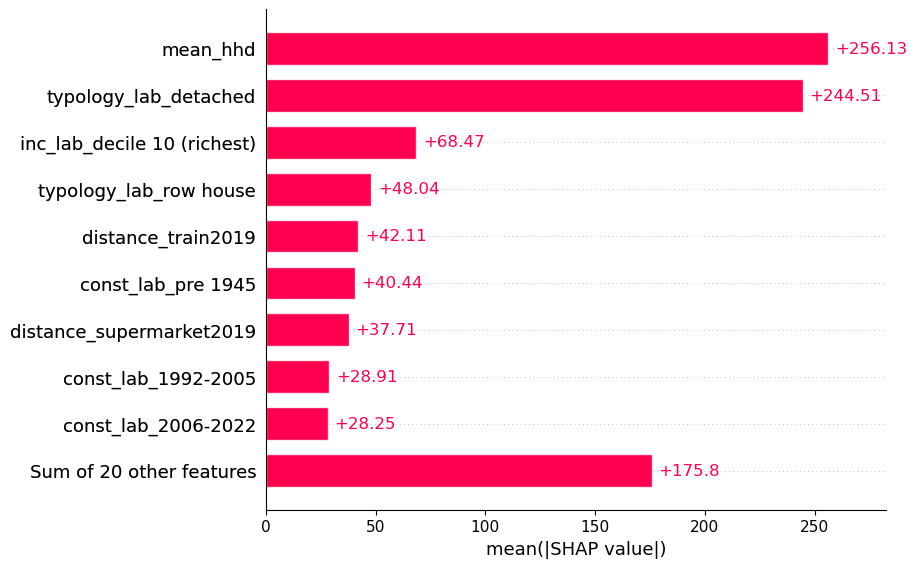

In [ ]:
# then the built in approach for showing variable importance, calculated different to the manual approach so can give different outputs, but tends to be broadly similar.
explainer = shap.Explainer(model, X)
shap_values_ex = explainer(X)
shap.plots.bar(shap_values_ex)

30it [00:12,  2.15s/it]                        


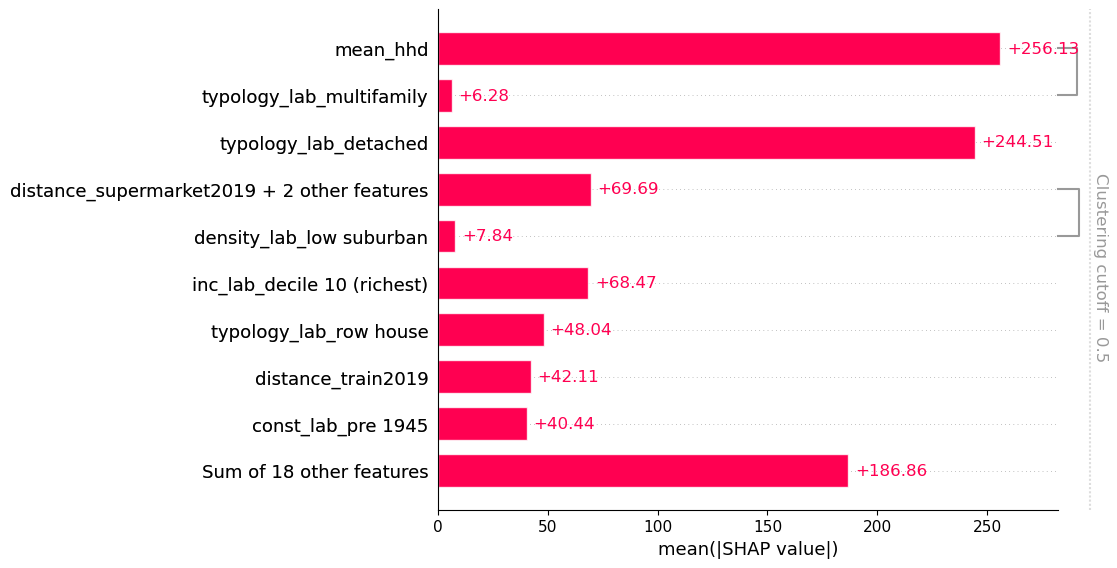

In [ ]:
#again the built in approach for showing variable imnportance, this time including clustering among related variabels
clustering = shap.utils.hclust(X, y)
shap.plots.bar(shap_values_ex, clustering=clustering)

0
1
2
3
4
5
6
7


Text(0.5, 0.92, 'Most important features for electricity consumption')

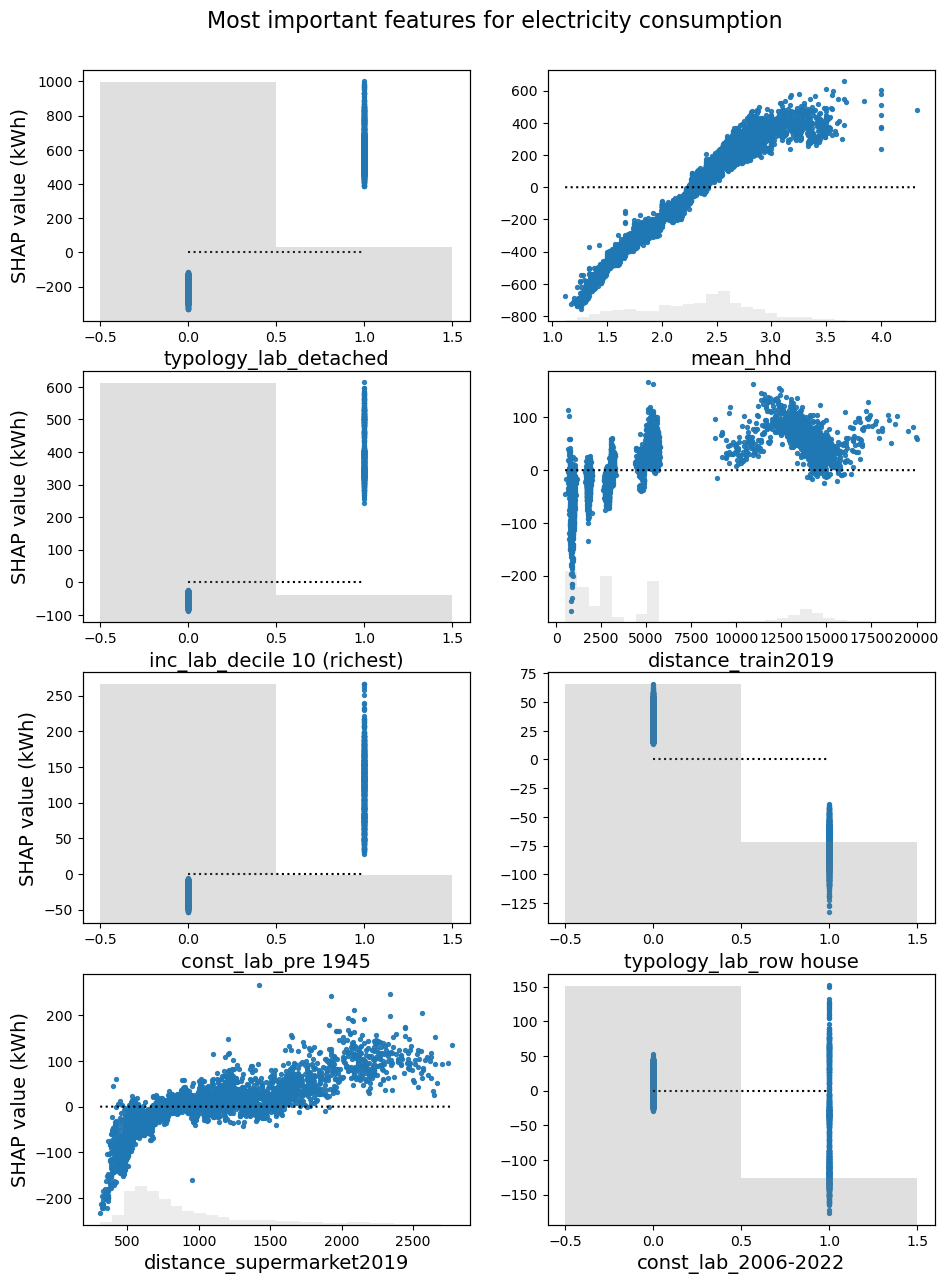

In [ ]:
# then show the range of influences (shap values) over the range of the x values
# this has the benefit of allowing us to see the direction of influence and potential non-linear influence of variables
n=importance_df[:10].index

X.sort_index(inplace=True)
data=X.sort_index().iloc[:,n]
values=shap_values.sort_index().iloc[:,n]

xl=[]
yl=[]
y0=[]

for i in range(len(n)):
        dftemp=pd.DataFrame({'d':data.iloc[:,i],'v':values.iloc[:,i]})
        dftemp=dftemp.groupby('d')['v'].mean().reset_index()
        dftemp['v0']=0
        xl.append(dftemp['d'].values)
        yl.append(dftemp['v'].values)
        y0.append(dftemp['v0'].values)



# plot the conditional shap values (accounting for influences of other variables) for the top N most influential variables.
# here we choose the top 8. this can be changed by altering the range, and then the dimensions of the subplot (42 for 8, 32 for 6, etc.)

fig = plt.figure(figsize=(11,15))
for i in range(0,8):
        print(i)
        ax1 = fig.add_subplot(421+i)
        xs=data.iloc[:,i]
        ys=values.iloc[:,i]
        x=xl[i]
        y1=y0[i]
        y2=yl[i]
        xlab=data.columns[i]

        ax1.scatter(xs,ys,alpha=0.9,s=8)
        plt.plot(x,y1,'k:',label='zero')

        if i%2==0:
                ax1.set_ylabel('SHAP value (kWh)',size=14)
        else:
                ax1.set_ylabel('')
        ax1.set_xlabel(xlab,size=14)

        ax2 = ax1.twinx() 
        if len(xs.unique())==2:
                ax2.hist(xs,bins=[-0.5,0.5,1.5], align='mid',color='gray',alpha=0.25)
                ax2.set_xticks([-.5,0,0.5,1,1.5])
        else:
                ax2.hist(xs,bins=30,color='gray',alpha=0.15)
                ax2.set_ylim(0,len(data))
        ax2.set_yticks([])
plt.suptitle("Most important features for electricity consumption",y=0.92,size=16)

In [ ]:
np.__version__

'1.23.4'

In [ ]:
# nicer looking linear regression summary, but this is jus from the last iteration of the linear regression, not the average.
lin_reg.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     netelectricity2019   R-squared:                       0.841
Model:                            OLS   Adj. R-squared:                  0.840
Method:                 Least Squares   F-statistic:                     986.2
Date:                Mon, 17 Mar 2025   Prob (F-statistic):               0.00
Time:                        14:20:49   Log-Likelihood:                -32475.
No. Observations:                4698   AIC:                         6.500e+04
Df Residuals:                    4672   BIC:                         6.517e+04
Df Model:                          25                                         
Covariance Type:            nonrobust                                         
================================================================================================================================================
                                                                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                     2131.5156     50.074     42.568      0.000    2033.348    2229.683
C(inc_lab, Treatment(reference='decile 1 (poorest)'))[T.decile 10 (richest)]   496.6613     16.908     29.374      0.000     463.513     529.809
C(inc_lab, Treatment(reference='decile 1 (poorest)'))[T.decile 2]             -116.1307     16.060     -7.231      0.000    -147.617     -84.645
C(inc_lab, Treatment(reference='decile 1 (poorest)'))[T.decile 3]             -132.4485     15.949     -8.304      0.000    -163.717    -101.180
C(inc_lab, Treatment(reference='decile 1 (poorest)'))[T.decile 4]              -95.7660     16.150     -5.930      0.000    -127.427     -64.105
C(inc_lab, Treatment(reference='decile 1 (poorest)'))[T.decile 5]              -54.7089     16.378     -3.340      0.001     -86.817     -22.601
C(inc_lab, Treatment(reference='decile 1 (poorest)'))[T.decile 6]              -28.8741     16.424     -1.758      0.079     -61.073       3.325
C(inc_lab, Treatment(reference='decile 1 (poorest)'))[T.decile 7]               -1.1681     16.547     -0.071      0.944     -33.608      31.271
C(inc_lab, Treatment(reference='decile 1 (poorest)'))[T.decile 8]               55.2381     16.782      3.292      0.001      22.338      88.138
C(inc_lab, Treatment(reference='decile 1 (poorest)'))[T.decile 9]              143.8384     17.016      8.453      0.000     110.479     177.198
C(typology_lab, Treatment(reference='detached'))[T.multifamily]               -830.3315     15.380    -53.987      0.000    -860.484    -800.179
C(typology_lab, Treatment(reference='detached'))[T.row house]                 -780.9503     10.708    -72.933      0.000    -801.943    -759.958
C(typology_lab, Treatment(reference='detached'))[T.semi-detached]             -642.9218     10.561    -60.877      0.000    -663.626    -622.217
C(const_lab, Treatment(reference='pre 1945'))[T.1946-1964]                    -169.3434     12.242    -13.833      0.000    -193.344    -145.343
C(const_lab, Treatment(reference='pre 1945'))[T.1965-1974]                    -130.3030     12.394    -10.514      0.000    -154.600    -106.006
C(const_lab, Treatment(reference='pre 1945'))[T.1975-1991]                    -159.1205     12.495    -12.735      0.000    -183.616    -134.625
C(const_lab, Treatment(reference='pre 1945'))[T.1992-2005]                     -59.2969     12.754     -4.649      0.000     -84.301     -34.293
C(const_lab, Treatment(reference='pre 1945'))[T.2006-2022]                    -274.2870     13.629    -20.126      0.000    -301.006    -247.568
C(density_lab, Treatment(reference='ru